# **UNIVERSIDAD DE LOS ANDES**
## **Técnicas de Deep Learning**
### **Calificacion de imagenes Medicas con CNNs**

- **SERGIO MASSO GIRALDO**

### ***Objetivo.***

El procesamiento de imágenes mediante redes neuronales convolucionales (CNN)
involucra múltiples capas de convolución, activación y pooling, que permiten extraer y analizar características relevantes de las imágenes. Estas técnicas facilitan una distinción precisa entre distintos tipos de tumores y el tejido sano, mejorando la exactitud del diagnóstico médico

El objetivo es desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraídas de MRIs en una de las 4 categorías

- Glioma
- Healthy
- Meningioma
- Pituitary

### ***Actividades por realizar***
1. Preparación de las imágenes para el entrenamiento y prueba del modelo. Construya un pipeline para cargar las imágenes y dividirlas en conjuntos de entrenamiento y prueba.
2. Desarrollo de la arquitectura de red neuronal convolucional para clasificación de las imágenes de MRI en una de las 4 categorías. La arquitectura es de libre elección, se recomienda utilizar bloques de convolución y max pooling o usar redes existentes y hacerles finetunning para este problema

### ***Descargar conjunto de datos de Brain Tumor mr Scans***

Usamos la funcion de kagglehub para la descraga automatica del conjunto de datos

In [1]:
%pip install kagglehub
%pip install torch torchvision
%pip install matplotlib
%pip install scikit-learn
%pip install seaborn
%pip install albumentations
%pip install pillow
%pip install numpy
!apt-get update -qq
!apt-get -qq install graphviz
!apt-get install -y graphviz
!pip install -q torchview


[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9

In [2]:
# Celda con la importación de librerías
import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import albumentations as A
from albumentations.pytorch import ToTensorV2
from collections import Counter
from PIL import Image
import copy
import time
import numpy as np               # Librería para trabajar con datos matriciales
import os
import random
from pathlib import Path
import hashlib
from collections import defaultdict
from sklearn.model_selection import train_test_split
from torchview import draw_graph
from PIL import Image as PILImage
from IPython.display import display, Image as DisplayImage

# Inicialización de semillas
torch.manual_seed(42)
np.random.seed(42)

# Dispositivo de cómputo (usa GPU si está disponible)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using device: {device}')

Using device: cuda


### ***Analisis Inicial del Conjunto de datos - EDA***

Dentro de este proceso primero se realizara un analisis profundo del conjunto de datos, resolviendo preguntas como:
- ¿Cuántas imágenes tiene cada clase?
- ¿Qué dimensiones tienen las imágenes originales?
- ¿Son imágenes RGB, escala de grises o una mezcla?
- ¿Las clases están equilibradas?
- ¿Hay imágenes dañadas, duplicadas o diferencias importantes entre las clases?

Estas preguntas nos ayudara aclarar con que conjunto de datos estamos trabajando y que procesamiento debemos de aplicar para que la CNNs pueda aprender de una mejor manera y entregar mejores resultados. El procesamiento en los datos nos sirve para poder dar un conjunto mas limpio y eficiente a la red evitanto que entre en sesgos o problemas de calificacion.

In [3]:
# Download latest version
path = kagglehub.dataset_download("rm1000/brain-tumor-mri-scans")

print("Path to dataset files:", path)

100%|██████████| 236M/236M [00:02<00:00, 112MB/s]  

Extracting model files...


Path to dataset files: /root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1



Carpeta: meningioma
Cantidad de elementos: 1645

Carpeta: healthy
Cantidad de elementos: 2000

Carpeta: glioma
Cantidad de elementos: 1621

Carpeta: pituitary
Cantidad de elementos: 1757


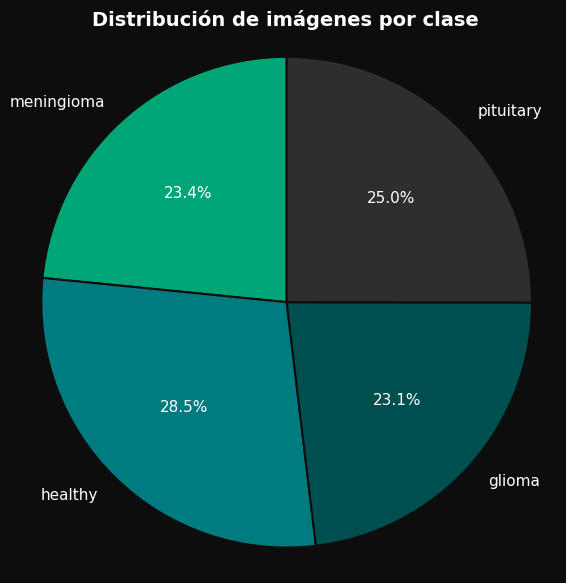

In [4]:
# Visualizacion de distribucion y balanceo de clases
CLASSES = ["glioma", "healthy", "meningioma", "pituitary"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
class_counts = {}

for carpeta in os.listdir(path):
    ruta_carpeta = os.path.join(path, carpeta)
    if os.path.isdir(ruta_carpeta):
        archivos = [
            f for f in os.listdir(ruta_carpeta)
            if os.path.splitext(f)[1].lower() in IMAGE_EXTENSIONS
        ]
        class_counts[carpeta] = len(archivos)
        print(f"\nCarpeta: {carpeta}")
        print(f"Cantidad de elementos: {len(archivos)}")

# Visualización con estilo radiográfico oscuro
labels = list(class_counts.keys())
sizes = list(class_counts.values())

# Paleta inspirada en radiología: verde clínico y tonos oscuros
medical_dark_colors = ["#00A676", "#007B7F", "#004F4F", "#2E2E2E"]
plt.figure(figsize=(7,7), facecolor="#0D0D0D")  # fondo oscuro
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=medical_dark_colors,
    textprops={'color': 'white', 'fontsize': 11},
    wedgeprops={'edgecolor': '#0D0D0D', 'linewidth': 1.5}
)
plt.title("Distribución de imágenes por clase",
          fontsize=14, weight='bold', color='white')
plt.axis('equal')
plt.show()

Dentro de la visual podemos apreciar que no existe un desbalanceo evidenten en el conjunto de datos aunque las imagenes "Sanas" representan una mayor proporcion no es un conjunto que pueda llegar afectar o sesgar el modelo a la hora de realizar la calificacion, por lo cual en esta parte descartamos temas como: Balanceo de clases sobremuestreo ni submuestreo.

In [5]:
print(Image)
print(type(Image))
print(hasattr(Image, "open"))

<module 'PIL.Image' from '/usr/local/lib/python3.8/dist-packages/PIL/Image.py'>
<class 'module'>
True


In [6]:
# Creamos codigo para realizar un analisis de dimensionalidad de las imagenes, tipo de color que estan entrando y tipo de archivo que se manejan.
image_sizes = Counter()
image_modes = Counter()
image_formats = Counter()
corrupted_images = []

# Realizamos iteracion para cada una de las carpetas para realizar la agrupacion total de cada imagen dependiendo de la clase
for class_name in CLASSES:
    class_dir = Path(path) / class_name

    if not class_dir.is_dir():
        continue

    for img_path in class_dir.rglob("*"):
        if not img_path.is_file():
            continue

        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(img_path) as img:
                image_sizes[img.size] += 1
                image_modes[img.mode] += 1
                image_formats[img.format] += 1
        except Exception as error:
            corrupted_images.append((str(img_path), str(error)))

# Ver resultados de la iteracion creada
print("Dimensiones más frecuentes:")
for size, count in image_sizes.most_common(15):
    print(f"{size}: {count} imágenes")

print("\nModos de color:")
for mode, count in image_modes.items():
    print(f"{mode}: {count}")

print("\nFormatos:")
for fmt, count in image_formats.items():
    print(f"{fmt}: {count}")

print("\nImágenes que no se pudieron leer:", len(corrupted_images))

Dimensiones más frecuentes:
(512, 512): 4742 imágenes
(225, 225): 332 imágenes
(630, 630): 90 imágenes
(236, 236): 81 imágenes
(201, 251): 58 imágenes
(228, 221): 51 imágenes
(232, 217): 50 imágenes
(300, 168): 49 imágenes
(442, 442): 46 imágenes
(150, 198): 44 imágenes
(200, 252): 43 imágenes
(428, 417): 42 imágenes
(227, 222): 39 imágenes
(173, 201): 36 imágenes
(206, 244): 35 imágenes

Modos de color:
RGB: 7023

Formatos:
JPEG: 7023

Imágenes que no se pudieron leer: 0


De acuerdo con lo encontrado se evidencia que dentro del conjunto de datos se presentan diferentes dimensionalidades en las radiograficas por lo cual sera necesario pasarlas o normalizar el conjunto de datos a un formato unico.

Adicional las imagenes no estan en una escala de grises si no que en formato RGB por lo cual mantendremos este formato para la red.

Se confirma que todas las imagenes vienen en JPEG por lo cual el cargue de los datos en el pipeline a construir solo tendra en cuenta este tipo de extension.

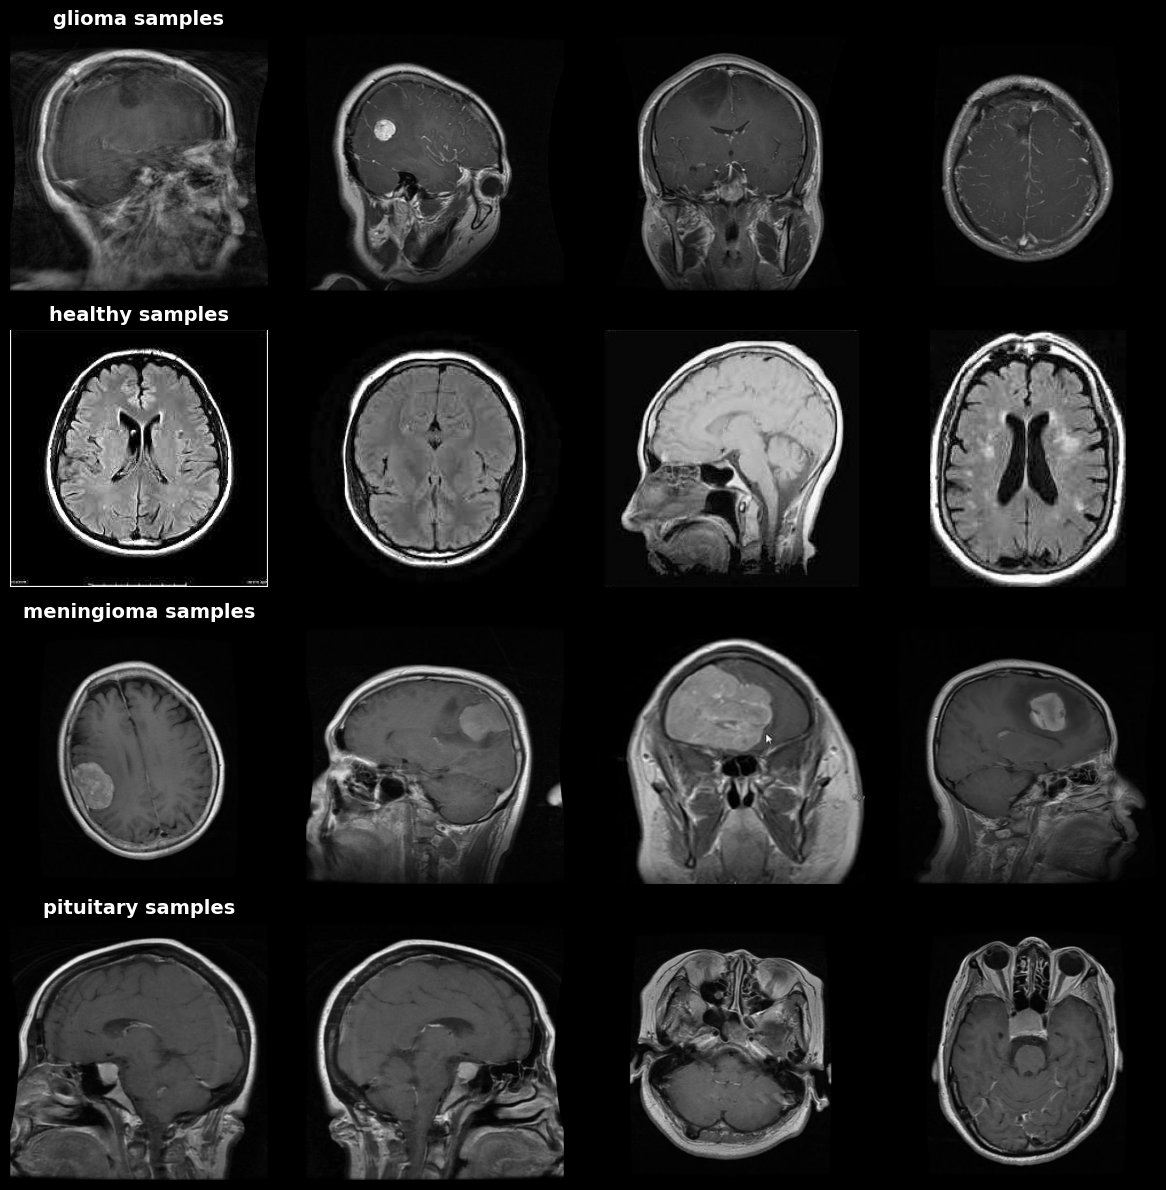

In [7]:
def show_class_samples(data_dir=path, classes=CLASSES, num_samples=4):
    fig, axes = plt.subplots(len(classes), num_samples, figsize=(num_samples * 3, len(classes) * 3))
    fig.patch.set_facecolor("#000")

    for i, cls in enumerate(classes):
        class_dir = os.path.join(data_dir, cls)
        images = random.sample(os.listdir(class_dir), num_samples)
        for j, img_name in enumerate(images):
            img_path = os.path.join(class_dir, img_name)
            img = Image.open(img_path)
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
            axes[i, j].set_facecolor("#0D0D0D")
            if j == 0:
                axes[i, j].set_title(f"{cls} samples", fontsize=14, color="white", weight="bold")

    plt.tight_layout()
    plt.show()

classes = ['glioma', 'healthy', 'meningioma', 'pituitary']
show_class_samples()

In [8]:
hash_to_files = defaultdict(list)

for class_name in CLASSES:

    class_dir = Path(path) / class_name

    if not class_dir.is_dir():
        continue

    for img_path in class_dir.rglob("*"):

        if not img_path.is_file():
            continue

        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            digest = hashlib.sha256(img_path.read_bytes()).hexdigest()
            hash_to_files[digest].append(str(img_path))
        except OSError:
            pass

duplicates = {
    digest: files
    for digest, files in hash_to_files.items()
    if len(files) > 1
}

print("Grupos de archivos duplicados:", len(duplicates))

for files in list(duplicates.values())[:10]:
    print("\n", *files, sep="\n")

Grupos de archivos duplicados: 300


/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/glioma/1525.jpg
/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/glioma/1579.jpg


/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0844.jpg
/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0994.jpg


/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1500.jpg
/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1812.jpg


/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0218.jpg
/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1506.jpg


/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1458.jpg
/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1892.jpg
/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versio

Al parecer se encuentran datos o imagenes duplicadas por lo cual se entrara a revisar estas imagenes de manera individual para determinar si son o no duplicados que puedan afectar en el entrenamiento de CNNs

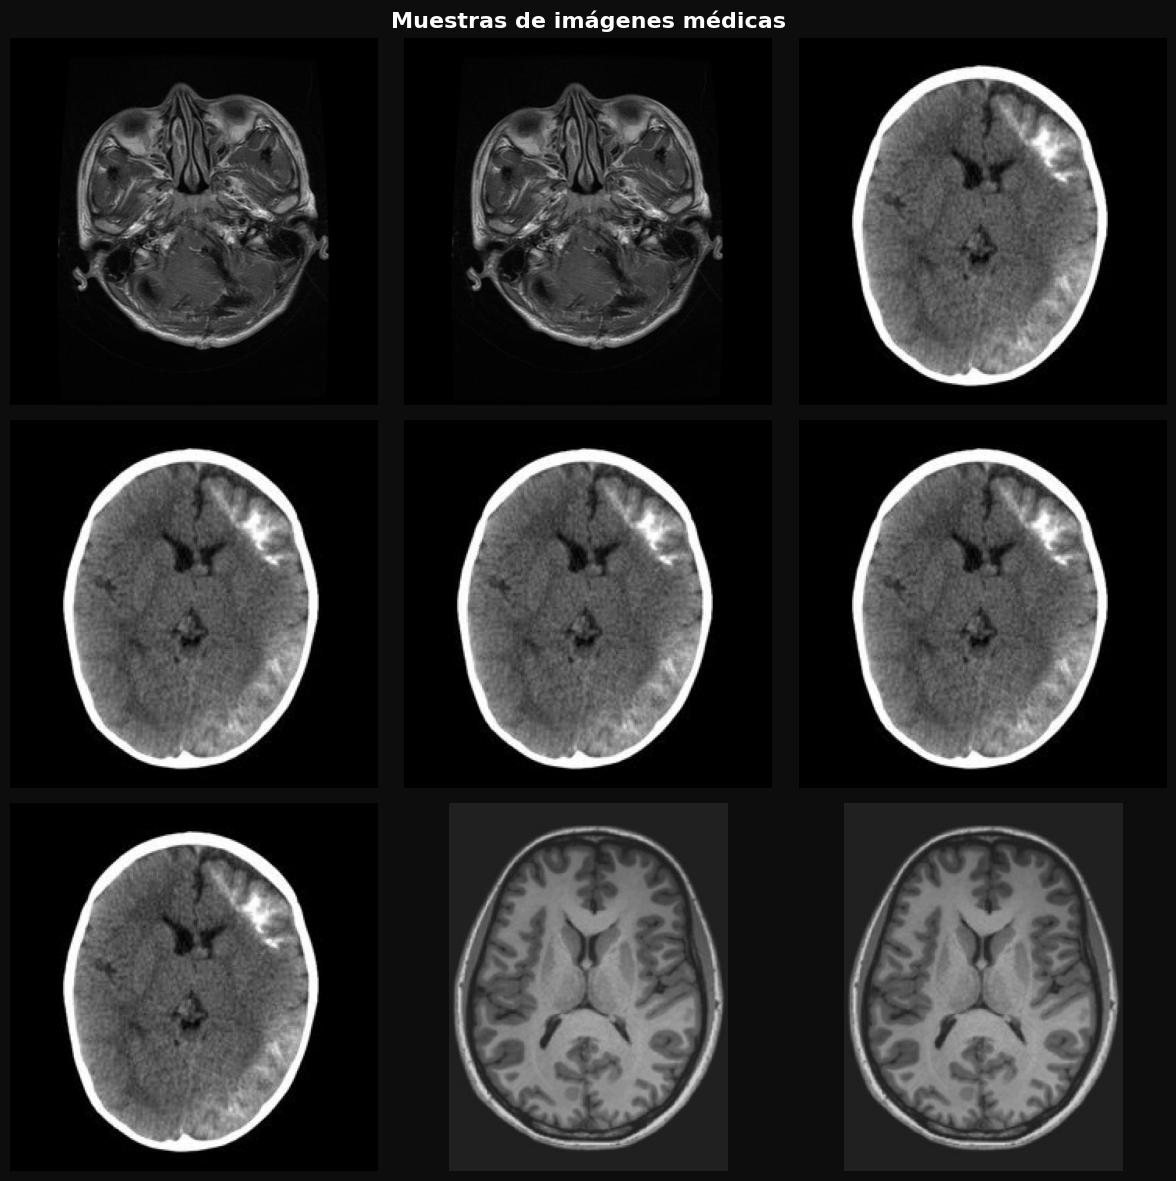

In [9]:
# Visualizacion de imagenes duplicadas

# Lista de rutas de las imagenes duplicadas
image_paths = [
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/glioma/1579.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/glioma/1525.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1614.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1450.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0144.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0600.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/1632.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0821.jpg",
    "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/healthy/0827.jpg"
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.patch.set_facecolor("#0D0D0D")

for ax, img_path in zip(axes.flat, image_paths):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.axis("off")
    ax.set_facecolor("#0D0D0D")

plt.suptitle("Muestras de imágenes médicas", fontsize=16, color="white", weight="bold")
plt.tight_layout()
plt.show()

Como se pueden ver para el conjunto de las imagenes seleccionadas, se evidencia que efectivamente estas imagenes estan repetidas dentro de nuestro conjunto de datos, esto puede provocar que imagenes se vayan para entrenamiento y otras para testeo o prueba, por lo cual podriamos estar entrenando y probando con imagenes duplicadas y alterar el rendimiendo de CNNs

In [10]:
# Contar todas las imágenes en el dataset
total_images = 0
for class_name in CLASSES:
    class_dir = Path(path) / class_name
    if not class_dir.is_dir():
        continue
    for img_path in class_dir.rglob("*"):
        if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXTENSIONS:
            total_images += 1

# Contar cuántas imágenes están duplicadas
duplicate_images = sum(len(files) for files in duplicates.values())

# Contar cuántas imágenes son "copias extra"
duplicate_copies = duplicate_images - len(duplicates)

print(f"Total de imágenes: {total_images:,}")
print(f"Imágenes duplicadas (incluyendo originales): {duplicate_images:,}")
print(f"Copias extra (las que sobran): {duplicate_copies:,}")
print(f"Porcentaje de duplicadas: {duplicate_images / total_images * 100:.2f}%")


Total de imágenes: 7,023
Imágenes duplicadas (incluyendo originales): 726
Copias extra (las que sobran): 426
Porcentaje de duplicadas: 10.34%


In [11]:
# Clasificar duplicados por carpeta
duplicates_by_class = defaultdict(list)
cross_class_duplicates = []

for digest, files in duplicates.items():
    # Extraer la carpeta/clase de cada archivo
    classes_in_group = {Path(f).parent.name for f in files}

    if len(classes_in_group) == 1:
        # Todos los duplicados están en la misma carpeta
        cls = list(classes_in_group)[0]
        duplicates_by_class[cls].append(files)
    else:
        # Hay duplicados que se repiten en varias carpetas
        cross_class_duplicates.append(files)

print("Duplicados dentro de la misma clase:")
for cls, groups in duplicates_by_class.items():
    print(f"{cls}: {len(groups)} grupos")

print("\nDuplicados entre clases distintas:", len(cross_class_duplicates))


Duplicados dentro de la misma clase:
glioma: 1 grupos
healthy: 178 grupos
meningioma: 107 grupos
pituitary: 14 grupos

Duplicados entre clases distintas: 0


### ***Creacion de Pipeline de datos***

Se implementará una clase dedicada al procesamiento integral de los datos, que abarcará las etapas de **carga, transformación y preparación**.  

El objetivo principal es garantizar que los datos queden listos para su uso en modelos de **redes neuronales convolucionales (CNNs)**, asegurando consistencia, escalabilidad y reproducibilidad en el flujo de trabajo teniendo en cuenta los analisis previos encontrados.

1. No se aplicara balanceo de clases ya que las clases se encuentran balanceadas
2. Se aplicara redimensionamiento y normalización de las radiograficas para que todas tengan el mismo tamnaño
3. No se aplicara o creara datos sinteticos.
4. Se dejara el formato RGB por defecto
5. Se eliminaran duplicados (Representa el 10% del conjunto de datos)
6. Se creara y separar los conjuntos de datos correspondientes en conjuntos de entrenamiento y prueba.

In [12]:
class BrainTumorDataset(Dataset):
    """
    Dataset de imágenes MRI para clasificación multiclase.
    """

    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, label = self.samples[idx]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

            if self.transform:
                image = self.transform(image)

        return image, label

In [13]:
class BrainTumorDataPipeline:
    """
    Pipeline de carga y preparación de imágenes MRI.

    Operaciones:
        - Carga de imágenes y etiquetas.
        - Eliminación de duplicados exactos.
        - División estratificada train/test.
        - Conversión a RGB.
        - Redimensionamiento.
        - Normalización de píxeles a [0, 1].
        - Creación de DataLoaders.
    """

    CLASSES = ["glioma","healthy","meningioma","pituitary"]
    EXTENSIONS = {".jpg", ".jpeg", ".png",".bmp", ".webp", ".tif", ".tiff"}

    def __init__(self,data_dir,image_size=128,test_size=0.20,batch_size=32,random_state=42,num_workers=2):
        self.data_dir = Path(path)
        self.image_size = image_size
        self.test_size = test_size
        self.batch_size = batch_size
        self.random_state = random_state
        self.num_workers = num_workers

        if not self.data_dir.is_dir():
            raise FileNotFoundError(f"No se encuentro el directorio: {self.data_dir}")

        if not 0 < test_size < 1:
            raise ValueError("test_size debe estar entre 0 y 1.")

        # Las imágenes se redimensionan y se convierten
        # a tensores float32 con píxeles en [0, 1].
        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor()
        ])

        self.class_to_idx = {name: idx for idx, name in enumerate(self.CLASSES)}
        self.idx_to_class = {idx: name for name, idx in self.class_to_idx.items()}

        self.train_dataset = None
        self.test_dataset = None
        self.train_loader = None
        self.test_loader = None

    @staticmethod
    def _get_image_hash(image_path):
        """
        Hash del contenido RGB decodificado.
        Detecta copias exactas, aunque cambie el formato
        del archivo, siempre que sus píxeles RGB sean iguales.
        """
        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img.load()

            content = (
                str(img.size).encode("utf-8")
                + img.tobytes()
            )

        return hashlib.sha256(content).hexdigest()

    def _load_unique_samples(self):
        """
        Carga las rutas y etiquetas y excluye duplicados
        exactos. Conserva una sola copia por grupo.
        """

        hash_groups = defaultdict(list)

        for class_name in self.CLASSES:
            class_dir = self.data_dir / class_name

            if not class_dir.is_dir():
                raise FileNotFoundError(f"No existe la carpeta de clase: {class_dir}")

            for image_path in sorted(class_dir.rglob("*")):
                if (not image_path.is_file() or image_path.suffix.lower() not in self.EXTENSIONS):
                    continue

                try:
                    image_hash = self._get_image_hash(image_path)
                    hash_groups[image_hash].append((image_path,self.class_to_idx[class_name]))

                except Exception as error:
                    raise RuntimeError(f"No se pudo leer la imagen {image_path}") from error

        samples = []

        for group in hash_groups.values():
            # Si una misma imagen aparece en distintas clases,
            # no podemos asignarle una etiqueta arbitrariamente.
            labels = {label for _, label in group}

            if len(labels) > 1:
                paths = [str(p) for p, _ in group]

                raise ValueError(
                    "Se encontró una imagen duplicada con "
                    "etiquetas diferentes. Revisa estos archivos:\n"
                    + "\n".join(paths)
                )

            # Conservar una sola copia.
            samples.append(min(group, key=lambda item: str(item[0])))

        samples.sort(key=lambda item: str(item[0]))

        return samples

    def prepare_data(self):
        """
        Ejecuta el pipeline y devuelve:
            train_loader, test_loader
        """
        # 1. Cargar imágenes y eliminar duplicados exactos
        samples = self._load_unique_samples()

        if not samples:
            raise ValueError("No se encontraron imágenes válidas.")

        labels = np.array([label for _, label in samples])

        # 2. División estratificada
        indices = np.arange(len(samples))
        train_idx, test_idx = train_test_split(indices,test_size=self.test_size,random_state=self.random_state,stratify=labels)
        train_samples = [samples[i] for i in train_idx]
        test_samples = [samples[i] for i in test_idx]

        # 3. Crear datasets independientes
        self.train_dataset = BrainTumorDataset(
            train_samples,
            transform=self.transform
        )

        self.test_dataset = BrainTumorDataset(
            test_samples,
            transform=self.transform
        )

        # 4. Crear DataLoaders
        generator = torch.Generator().manual_seed(
            self.random_state
        )

        self.train_loader = DataLoader(
            self.train_dataset,                  # Dataset
            batch_size=self.batch_size,          # Número de muestras por batch
            shuffle=True,                        # Barajar datos en cada época
            num_workers=self.num_workers,        # Procesos paralelos para cargar datos
            generator=generator,                 # Control de aleatoriedad (semilla reproducible)
            pin_memory=torch.cuda.is_available() # Optimiza transferencia a GPU
        )

        self.test_loader = DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=torch.cuda.is_available()
        )

        print("Pipeline completado.")
        print(f"Imágenes únicas: {len(samples)}")
        print(f"Entrenamiento: {len(train_samples)}")
        print(f"Prueba: {len(test_samples)}")
        print(f"Tamaño: {self.image_size} x {self.image_size}")
        print("Canales: RGB")
        print("Normalización: [0, 1]")

        return self.train_loader, self.test_loader

In [14]:
# Se instancia la clase BrainTumorDataPipeline con los parametros correspondientes
# Se define un tamaño de imagen de 224 debido a que el tamnaño original es de (512, 512) para no perder mucha informacion se deja en 224
# Se define el % para entrenamiento y prueba.

pipeline = BrainTumorDataPipeline(
    data_dir=path,  # Lugar donde esta la data
    image_size=224, # Tamaño de la imagen seleccionado
    test_size=0.20, # 80 % Prueba y 20 % Test
    batch_size=32,  # Tamaño del batch
    random_state=42 # Semilla
)

train_loader, test_loader = pipeline.prepare_data()

Pipeline completado.
Imágenes únicas: 6597
Entrenamiento: 5277
Prueba: 1320
Tamaño: 224 x 224
Canales: RGB
Normalización: [0, 1]


In [15]:
images, labels = next(iter(train_loader))

print("Forma de las imágenes:", images.shape)
print("Forma de las etiquetas:", labels.shape)
print("Tipo de dato:", images.dtype)
print("Valor mínimo:", images.min().item())
print("Valor máximo:", images.max().item())

Exception in thread Thread-7:
Traceback (most recent call last):
  File "/usr/lib/python3.8/threading.py", line 932, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.8/threading.py", line 870, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.8/dist-packages/torch/utils/data/_utils/pin_memory.py", line 54, in _pin_memory_loop
    do_one_step()
  File "/usr/local/lib/python3.8/dist-packages/torch/utils/data/_utils/pin_memory.py", line 31, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.8/multiprocessing/queues.py", line 116, in get
    return _ForkingPickler.loads(res)
  File "/usr/local/lib/python3.8/dist-packages/torch/multiprocessing/reductions.py", line 355, in rebuild_storage_fd
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7023c39ff280>
Traceback (most recent call last):
  File "/usr/local/lib/python3.8/dist-packages/torch/utils/data/dataloader.py", line 1478, 

Forma de las imágenes: torch.Size([32, 3, 224, 224])
Forma de las etiquetas: torch.Size([32])
Tipo de dato: torch.float32
Valor mínimo: 0.0
Valor máximo: 1.0


In [16]:
print(pipeline.class_to_idx)

{'glioma': 0, 'healthy': 1, 'meningioma': 2, 'pituitary': 3}


Despues del procesamiento realizado por el pipeline, nos deja los datos listos para ser usados por la CNNs que se creara acontionuacion. Dentro de todo el procesamiento se realizo la eliminacion de los duplicados la definicion de los canales el tamaño y separacion de los conjuntos de datos a usar junto con su normalizacion. 

Adicional obtenemos datos como las clases a calificar por la CNNs donde 0 sera glioma, 1 healthy, 2 meningioma, 3 pituitary 

En la primera capa convolucional se utilizan 32 filtros con un kernel de dimensión 3x3; esto significa que nuestra entrada, la cual se puede pensar como 3 matrices de 224x224 correspondientes a los canales RGB, luego de pasar por la capa de convolución tendrá 32 canales de salida.

En cada filtro se usa un kernel de 3x3, lo que implica 9 parámetros por cada canal de entrada. Como la entrada tiene 3 canales y existen 32 filtros, el total de parámetros es 32 * 9 * 3 = 864. Además, cada filtro tiene un sesgo asociado, por lo que se suman 32 parámetros más. En total, la capa convolucional contiene 896 parámetros.

Si no se aplica relleno (padding=0), la convolución reduce el tamaño espacial de la imagen: se eliminan una fila arriba y abajo, y una columna a la izquierda y derecha. Por lo tanto, la salida tendría dimensiones 222x222x32. En cambio, si se usa padding=1, se conserva el tamaño original y la salida sería 224x224x32.

### Visualizacion del conjunto de datos train_loader, test_loader

Para continuar con la creacion de la arquitectura y de una red existente primero vamos a realizar la visualizacion de los datos ya procesados para entender mas a fondo que se le estara entregando a la red convolucional (CNN)

In [17]:
train_loader

In [18]:
test_loader

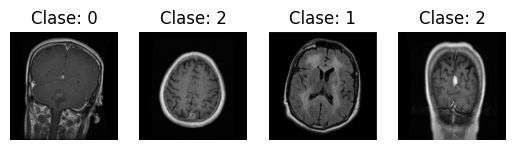

In [19]:
import matplotlib.pyplot as plt

# Mostrar las primeras 4 imágenes del batch
for i in range(4):
    img = images[i].permute(1, 2, 0).numpy()  # Cambiar de [C,H,W] a [H,W,C]
    label = labels[i].item()
    plt.subplot(1, 4, i+1)
    plt.imshow(img)
    plt.title(f"Clase: {label}")
    plt.axis("off")

plt.show()

In [20]:
images, labels = next(iter(train_loader))

# Seleccionamos la primera imagen del batch
img_tensor = images[0]

print("Forma:", img_tensor.shape)   # (3, 224, 224)
print("Tipo:", img_tensor.dtype)    # torch.float32
print("Valores (primer canal, primeras 5 filas y columnas):")
print(img_tensor[0, :5, :5])        # canal rojo, 5x5 píxeles

Forma: torch.Size([3, 224, 224])
Tipo: torch.float32
Valores (primer canal, primeras 5 filas y columnas):
tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0078, 0.0078, 0.0078, 0.0078, 0.0078],
        [0.0118, 0.0118, 0.0118, 0.0157, 0.0196],
        [0.0196, 0.0157, 0.0157, 0.0275, 0.0314],
        [0.0275, 0.0314, 0.0314, 0.0353, 0.0314]])


### 1. Desarrollo de una arquitectura de red neuronal convolucional propia para la clasificación de imágenes de MRI - Propia

#### 1.1. Descripción general de la arquitectura

En esta primera etapa se desarrollará una arquitectura de red neuronal convolucional (CNN) propia, diseñada para clasificar imágenes de resonancia magnética (MRI) cerebral en cuatro categorías: glioma, meningioma, tumor pituitario y cerebro sano. Para su implementación se utilizará la biblioteca PyTorch, mediante el módulo `torch.nn` y la clase `nn.Sequential`, que permiten organizar las capas de la red de manera secuencial.

La arquitectura estará compuesta por bloques de convolución y capas de *max pooling*, encargados de extraer características relevantes de las imágenes y reducir progresivamente sus dimensiones espaciales. Posteriormente, se incorporarán capas totalmente conectadas para realizar la clasificación final en las cuatro categorías establecidas.

El diseño de la red se realizará desde cero, definiendo la estructura y los parámetros de sus capas de acuerdo con las características del conjunto de datos y los objetivos del proyecto.

In [21]:
# Creacion de la Arquitectura de la Red Convolucional CNN 
# Se crea una clase para la creacion de la CNN junto con las caracteristicas necesarias para su funcionamiento
# La explicacion de la arquitectura estara presentada linea abajo

class BrainTumorCNN(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()
        # Extractor de características
        self.features = nn.Sequential(
            # Bloque 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            
            # Bloque 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Bloque 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Bloque 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Reducción a un vector de 256 características
            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Clasificador
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

#### 1.2. Estructura de la red neuronal

La estructura general del modelo es la siguiente:

1. **Entrada:** imágenes RGB de tamaño 224 × 224 píxeles.
2. **Bloques convolucionales:** cuatro capas convolucionales con 32, 64, 128 y 256 filtros, respectivamente, acompañadas de las funciones de activación ReLU y capas Max Pooling.
3. **Agrupamiento adaptativo:** reduce cada mapa de características a una dimensión espacial de 1 × 1.
4. **Clasificador:** una capa lineal de 256 a 128 neuronas, seguida de ReLU y Dropout (0.4).
5. **Salida:** una capa lineal de cuatro neuronas, una por cada clase: glioma, healthy, meningioma y pituitary.


In [22]:
# Se llama la clase y se crea el modelo
model = BrainTumorCNN(num_classes=4).to(device)

In [23]:
# Visualizacion del modelo creado para una sola entrada como ejemplo
# Generar el diagrama
model_graph = draw_graph(
    model,
    input_size=(1, 3, 224, 224),
    graph_name="BrainTumorCNN",
    expand_nested=True,
    device="cpu"
)

# Guardamos el diagrama como PNG para visualizarlo
model_graph.visual_graph.format = "png"

model_graph.visual_graph.render(
    filename="BrainTumorCNN",
    format="png",
    cleanup=True
)


'BrainTumorCNN.png'

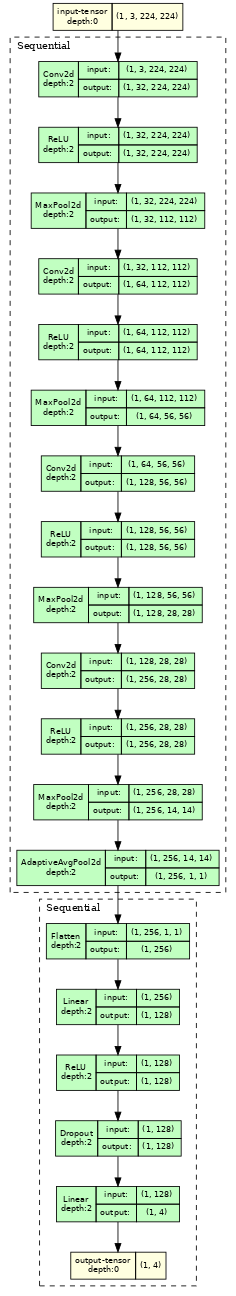

In [24]:
# Mostrar la imagen guardada
display(DisplayImage(filename="BrainTumorCNN.png", width=600))


#### 1.3. Justificación de las capas utilizadas

- **Convolución (`Conv2d`):** extrae características visuales, como bordes, texturas y patrones presentes en las imágenes ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)).

- **ReLU:** introduce no linealidad, permitiendo aprender relaciones más complejas ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html)).

- **Max Pooling:** reduce las dimensiones espaciales seleccionando el valor máximo dentro de regiones locales ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html)). Se utiliza una ventana de 2 × 2 con paso de 2, reduciendo aproximadamente a la mitad la altura y la anchura de los mapas de características.

- **Agrupamiento adaptativo (`AdaptiveAvgPool2d`):** resume cada mapa de características en un único valor, independientemente de sus dimensiones espaciales ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html)).

- **Aplanamiento (`Flatten`):** transforma los mapas de características en un vector para conectarlos con el clasificador ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.Flatten.html)).

- **Capas lineales (`Linear`):** combinan las características extraídas para determinar la clase correspondiente ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)).

- **Dropout (0.4):** desactiva aleatoriamente el 40 % de las neuronas de esa capa durante el entrenamiento para ayudar a reducir el sobreajuste ([PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html)).

La capa de salida genera cuatro valores (*logits*). Durante el entrenamiento se utiliza `CrossEntropyLoss`, por lo que no es necesario añadir una capa Softmax al modelo.

### Entrenamiento y Validacion de CNN Propia

In [25]:
def train_model(model, train_loader, optimizer, epochs=20):

    criterion = nn.CrossEntropyLoss() # Implementamos CrossEntropyLoss al modelo
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
    model = model.to(device) # Le indicamos que use gpu
    history = {
        "loss": [],
        "accuracy": []
    }  # Guardamos resultados para posterior analisis

    for epoch in range(epochs):
        model.train() # Entrenar modelo
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device).long()

            optimizer.zero_grad() # Reiniciar gradientes
            outputs = model(images) # Predicción
            loss = criterion(outputs, labels) # Calcular pérdida
            
            loss.backward() # Retropropagación y actualización
            optimizer.step()

            running_loss += loss.item() * images.size(0) # Acumular resultados

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_accuracy = correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        print(
            f"Época [{epoch + 1}/{epochs}] "
            f"| Loss: {epoch_loss:.4f} "
            f"| Accuracy: {epoch_accuracy:.2%}"
        )

    return model, history

In [26]:
def evaluate_model(model, test_loader):

    criterion = nn.CrossEntropyLoss()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0
    
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device).long()

            outputs = model(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            total_loss += loss.item() * images.size(0)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_predictions.extend(predictions.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    test_loss = total_loss / total
    test_accuracy = correct / total

    print("Resultados de evaluación")
    print("------------------------")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.2%}")

    print("\nReporte de clasificación:")
    print(classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1, 2, 3],
        target_names=["Glioma", "Healthy", "Meningioma", "Pituitary"],
        zero_division=0
    ))

    return test_loss, test_accuracy, all_labels, all_predictions

In [27]:
# Definir el optimizador
optimizer = optim.Adam(model.parameters(),lr=0.001)
# Entrenar
model, history = train_model(
    model=model,
    train_loader=train_loader,
    optimizer=optimizer,
    epochs=30
)

Época [1/30] | Loss: 1.1009 | Accuracy: 48.59%
Época [2/30] | Loss: 0.8885 | Accuracy: 63.16%
Época [3/30] | Loss: 0.7414 | Accuracy: 71.12%
Época [4/30] | Loss: 0.6727 | Accuracy: 73.38%
Época [5/30] | Loss: 0.6299 | Accuracy: 76.08%
Época [6/30] | Loss: 0.5991 | Accuracy: 77.17%
Época [7/30] | Loss: 0.5617 | Accuracy: 78.17%
Época [8/30] | Loss: 0.5386 | Accuracy: 79.61%
Época [9/30] | Loss: 0.5368 | Accuracy: 79.14%
Época [10/30] | Loss: 0.5401 | Accuracy: 78.57%
Época [11/30] | Loss: 0.5030 | Accuracy: 79.97%
Época [12/30] | Loss: 0.4893 | Accuracy: 80.48%
Época [13/30] | Loss: 0.4699 | Accuracy: 81.39%
Época [14/30] | Loss: 0.4748 | Accuracy: 81.35%
Época [15/30] | Loss: 0.4467 | Accuracy: 82.49%
Época [16/30] | Loss: 0.4433 | Accuracy: 82.91%
Época [17/30] | Loss: 0.4192 | Accuracy: 83.91%
Época [18/30] | Loss: 0.4241 | Accuracy: 83.70%
Época [19/30] | Loss: 0.3992 | Accuracy: 84.56%
Época [20/30] | Loss: 0.3854 | Accuracy: 85.11%
Época [21/30] | Loss: 0.3706 | Accuracy: 85.98%
É

In [28]:
results = evaluate_model(
    model=model,
    test_loader=test_loader
)

Resultados de evaluación
------------------------
Test Loss: 0.3181
Test Accuracy: 86.82%

Reporte de clasificación:
              precision    recall  f1-score   support

      Glioma       0.76      0.93      0.84       324
     Healthy       0.93      0.98      0.96       342
  Meningioma       0.88      0.57      0.69       306
   Pituitary       0.92      0.96      0.94       348

    accuracy                           0.87      1320
   macro avg       0.87      0.86      0.86      1320
weighted avg       0.87      0.87      0.86      1320



In [29]:
def visualization_history(history):

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    epochs = range(1, len(history["loss"]) + 1)

    # Curva de precisión
    axes[0].plot(
        epochs,
        history["accuracy"],
        marker="o",
        label="Precisión de entrenamiento"
    )
    axes[0].set_title("Precisión por época")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid()
    axes[0].legend()

    # Curva de pérdida
    axes[1].plot(
        epochs,
        history["loss"],
        marker="o",
        label="Pérdida de entrenamiento"
    )
    axes[1].set_title("Pérdida por época")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Loss")
    axes[1].grid()
    axes[1].legend()

    plt.tight_layout()
    plt.show()


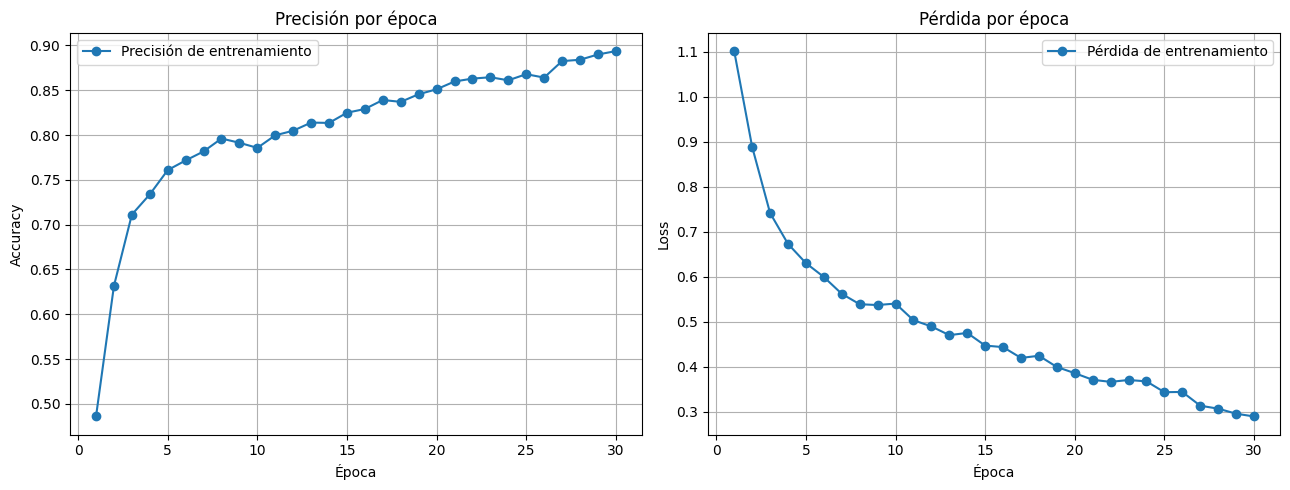

In [30]:
visualization_history(history)

In [31]:
# Supongamos que tu pipeline está en la variable 'pipeline'
img_path = "/root/.cache/kagglehub/datasets/rm1000/brain-tumor-mri-scans/versions/1/glioma/1579.jpg"

img = Image.open(img_path).convert("RGB")
img_tensor = pipeline.transform(img).unsqueeze(0) 

model.eval()
with torch.no_grad():
    output = model(img_tensor.to(device))
    pred_class = output.argmax(dim=1).item()

print("Predicción índice:", pred_class)
print("Clase predicha:", pipeline.idx_to_class[pred_class])


Predicción índice: 0
Clase predicha: glioma


### Aplicacion de transfer learning y fine-tuning a ResNet50



In [33]:
class BrainTumorDataPipeline:
    """
    Pipeline de carga y preparación de imágenes MRI para RestNet50.

    Operaciones:
        - Carga de imágenes y etiquetas.
        - Eliminación de duplicados exactos.
        - División estratificada train/test.
        - Conversión a RGB.
        - Redimensionamiento.
        - Normalización de píxeles a [0, 1].
        - Creación de DataLoaders.
    """

    CLASSES = ["glioma","healthy","meningioma","pituitary"]
    EXTENSIONS = {".jpg", ".jpeg", ".png",".bmp", ".webp", ".tif", ".tiff"}

    def __init__(self,data_dir,image_size=128,test_size=0.20,batch_size=32,random_state=42,num_workers=2):
        self.data_dir = Path(path)
        self.image_size = image_size
        self.test_size = test_size
        self.batch_size = batch_size
        self.random_state = random_state
        self.num_workers = num_workers

        if not self.data_dir.is_dir():
            raise FileNotFoundError(f"No se encuentro el directorio: {self.data_dir}")

        if not 0 < test_size < 1:
            raise ValueError("test_size debe estar entre 0 y 1.")

        # Las imágenes se redimensionan y se convierten
        # a tensores float32 con píxeles en [0, 1].
        # Dentro de la arquitectura para RestNet50 es necesario implementar el metodo Normalize implementando
        # Los campos de mean y std
        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])
        self.class_to_idx = {name: idx for idx, name in enumerate(self.CLASSES)}
        self.idx_to_class = {idx: name for name, idx in self.class_to_idx.items()}

        self.train_dataset = None
        self.test_dataset = None
        self.train_loader = None
        self.test_loader = None

    @staticmethod
    def _get_image_hash(image_path):
        """
        Hash del contenido RGB decodificado.
        Detecta copias exactas, aunque cambie el formato
        del archivo, siempre que sus píxeles RGB sean iguales.
        """
        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img.load()

            content = (
                str(img.size).encode("utf-8")
                + img.tobytes()
            )

        return hashlib.sha256(content).hexdigest()

    def _load_unique_samples(self):
        """
        Carga las rutas y etiquetas y excluye duplicados
        exactos. Conserva una sola copia por grupo.
        """

        hash_groups = defaultdict(list)

        for class_name in self.CLASSES:
            class_dir = self.data_dir / class_name

            if not class_dir.is_dir():
                raise FileNotFoundError(f"No existe la carpeta de clase: {class_dir}")

            for image_path in sorted(class_dir.rglob("*")):
                if (not image_path.is_file() or image_path.suffix.lower() not in self.EXTENSIONS):
                    continue

                try:
                    image_hash = self._get_image_hash(image_path)
                    hash_groups[image_hash].append((image_path,self.class_to_idx[class_name]))

                except Exception as error:
                    raise RuntimeError(f"No se pudo leer la imagen {image_path}") from error

        samples = []

        for group in hash_groups.values():
            # Si una misma imagen aparece en distintas clases,
            # no podemos asignarle una etiqueta arbitrariamente.
            labels = {label for _, label in group}

            if len(labels) > 1:
                paths = [str(p) for p, _ in group]

                raise ValueError(
                    "Se encontró una imagen duplicada con "
                    "etiquetas diferentes. Revisa estos archivos:\n"
                    + "\n".join(paths)
                )

            # Conservar una sola copia.
            samples.append(min(group, key=lambda item: str(item[0])))

        samples.sort(key=lambda item: str(item[0]))

        return samples

    def prepare_data(self):
        """
        Ejecuta el pipeline y devuelve:
            train_loader, test_loader
        """
        # 1. Cargar imágenes y eliminar duplicados exactos
        samples = self._load_unique_samples()

        if not samples:
            raise ValueError("No se encontraron imágenes válidas.")

        labels = np.array([label for _, label in samples])

        # 2. División estratificada
        indices = np.arange(len(samples))
        train_idx, test_idx = train_test_split(indices,test_size=self.test_size,random_state=self.random_state,stratify=labels)
        train_samples = [samples[i] for i in train_idx]
        test_samples = [samples[i] for i in test_idx]

        # 3. Crear datasets independientes
        self.train_dataset = BrainTumorDataset(
            train_samples,
            transform=self.transform
        )

        self.test_dataset = BrainTumorDataset(
            test_samples,
            transform=self.transform
        )

        # 4. Crear DataLoaders
        generator = torch.Generator().manual_seed(
            self.random_state
        )

        self.train_loader = DataLoader(
            self.train_dataset,                  # Dataset
            batch_size=self.batch_size,          # Número de muestras por batch
            shuffle=True,                        # Barajar datos en cada época
            num_workers=self.num_workers,        # Procesos paralelos para cargar datos
            generator=generator,                 # Control de aleatoriedad (semilla reproducible)
            pin_memory=torch.cuda.is_available() # Optimiza transferencia a GPU
        )

        self.test_loader = DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=torch.cuda.is_available()
        )

        print("Pipeline completado.")
        print(f"Imágenes únicas: {len(samples)}")
        print(f"Entrenamiento: {len(train_samples)}")
        print(f"Prueba: {len(test_samples)}")
        print(f"Tamaño: {self.image_size} x {self.image_size}")
        print("Canales: RGB")
        print("Normalización: [0, 1]")

        return self.train_loader, self.test_loader

In [34]:
pipeline = BrainTumorDataPipeline(
    data_dir=path,
    image_size=224,
    test_size=0.20,
    batch_size=32,
    random_state=42
)

train_loader, test_loader = pipeline.prepare_data()

Pipeline completado.
Imágenes únicas: 6597
Entrenamiento: 5277
Prueba: 1320
Tamaño: 224 x 224
Canales: RGB
Normalización: [0, 1]


In [35]:
class BrainTumorResNet(nn.Module):

    def __init__(self, num_classes=4, freeze_backbone=True):
        super().__init__()

        # Cargar ResNet50 con pesos preentrenados
        weights = models.ResNet50_Weights.DEFAULT
        self.model = models.resnet50(weights=weights)

        # Congelar inicialmente las capas preentrenadas
        if freeze_backbone:
            for param in self.model.parameters():
                param.requires_grad = False

        # Adaptar la capa final a las cuatro categorías
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

In [36]:
model_ResNet = BrainTumorResNet(num_classes=4,freeze_backbone=True).to(device)
optimizer_ResNet = torch.optim.Adam(model_ResNet.model.fc.parameters(),lr=0.001)
model_ResNet, history_ResNet = train_model(
    model_ResNet,
    train_loader,
    optimizer_ResNet,
    epochs=15
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 421MB/s]


Época [1/15] | Loss: 0.6656 | Accuracy: 80.92%
Época [2/15] | Loss: 0.3871 | Accuracy: 88.29%
Época [3/15] | Loss: 0.3211 | Accuracy: 90.37%
Época [4/15] | Loss: 0.2842 | Accuracy: 91.02%
Época [5/15] | Loss: 0.2582 | Accuracy: 91.72%
Época [6/15] | Loss: 0.2328 | Accuracy: 92.97%
Época [7/15] | Loss: 0.2171 | Accuracy: 93.20%
Época [8/15] | Loss: 0.2094 | Accuracy: 93.25%
Época [9/15] | Loss: 0.1943 | Accuracy: 93.82%
Época [10/15] | Loss: 0.1870 | Accuracy: 93.97%
Época [11/15] | Loss: 0.1821 | Accuracy: 94.05%
Época [12/15] | Loss: 0.1707 | Accuracy: 94.54%
Época [13/15] | Loss: 0.1631 | Accuracy: 94.86%
Época [14/15] | Loss: 0.1551 | Accuracy: 94.92%
Época [15/15] | Loss: 0.1572 | Accuracy: 95.11%


In [37]:
# Descongelar la última etapa convolucional
for param in model_ResNet.model.layer4.parameters():
    param.requires_grad = True

# Asegurar que la capa clasificadora siga entrenable
for param in model_ResNet.model.fc.parameters():
    param.requires_grad = True

# Crear el optimizador para el fine-tuning
optimizer_finetune_ResNet = torch.optim.Adam([
    {
        "params": model_ResNet.model.layer4.parameters(),
        "lr": 0.0001
    },
    {
        "params": model_ResNet.model.fc.parameters(),
        "lr": 0.0001
    }
])

# Continuar el entrenamiento
model_ResNet, history_finetune_ResNet = train_model(
    model_ResNet,
    train_loader,
    optimizer_finetune_ResNet,
    epochs=10
)

Época [1/10] | Loss: 0.1212 | Accuracy: 95.79%
Época [2/10] | Loss: 0.0213 | Accuracy: 99.51%
Época [3/10] | Loss: 0.0060 | Accuracy: 99.89%
Época [4/10] | Loss: 0.0037 | Accuracy: 99.96%
Época [5/10] | Loss: 0.0061 | Accuracy: 99.83%
Época [6/10] | Loss: 0.0057 | Accuracy: 99.85%
Época [7/10] | Loss: 0.0034 | Accuracy: 99.92%
Época [8/10] | Loss: 0.0048 | Accuracy: 99.85%
Época [9/10] | Loss: 0.0021 | Accuracy: 99.98%
Época [10/10] | Loss: 0.0086 | Accuracy: 99.75%


In [38]:
results_ResNet = evaluate_model(
    model=model_ResNet,
    test_loader=test_loader
)

Resultados de evaluación
------------------------
Test Loss: 0.1104
Test Accuracy: 97.12%

Reporte de clasificación:
              precision    recall  f1-score   support

      Glioma       0.97      0.98      0.97       324
     Healthy       0.99      0.98      0.98       342
  Meningioma       0.94      0.94      0.94       306
   Pituitary       0.98      0.98      0.98       348

    accuracy                           0.97      1320
   macro avg       0.97      0.97      0.97      1320
weighted avg       0.97      0.97      0.97      1320

